# задание 1 - дд 7.10 23.59
# Построение модели вероятности дефолта на датасете give me some credit

## 1. загрузка и очистка данных:

In [2]:
!pip install lightgbm shap -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import warnings

warnings.filterwarnings('ignore')
# настройки отображения
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [3]:
df = pd.read_csv('GiveMeSomeCredit-training.csv', sep=',')

df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


интерпретация столбцов:
1. SeriousDlqin2yrs - cерьезная просрочка в течение 2 лет (0 - хорошка, 1 - плохой)

2. RevolvingUtilizationOfUnsecuredLines - насколько сильно человек залез в кредитки (чем выше число, тем ближе человек к финансовому краю)

3. NumberOfTime30-59DaysPastDueNotWorse - сколько раз за последние 2 года человек задерживал платеж на месяц

4. NumberOfTime60-89DaysPastDueNotWorse - задержка на 2 месяца

5. NumberOfTimes90DaysLate - колво просрочек 90+ дней

6. DebtRatio - сколько процентов от зарплаты уходит на выплаты

7. NumberOfOpenCreditLinesAndLoans - колво открытых кредитов и займов

8. NumberRealEstateLoansOrLines - колво кредитов по недвижке и кредитных линий

9. NumberOfDependents - сколько человек находится на обеспечении заемщика

In [4]:
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

# чистка
cols_delinq = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']
for col in cols_delinq:
    df[f'{col}_code_9x'] = df[col].isin([96, 98]).astype(int)
    # замена спец кодов на NaN (LightGBM обработает как пропуски)
    df[col] = df[col].replace([96, 98], np.nan)

df = df[df['age'] > 0]

df['RevolvingUtilizationOfUnsecuredLines'] = df['RevolvingUtilizationOfUnsecuredLines'].clip(upper=1.0)

print(f"размер данных после очистки: {df.shape}")

размер данных после очистки: (149999, 14)


**примечание про флаг:** замена 96/98 на 0 искажает данные, ошибочно обелит клиента, тогда как флаг code_9x + NaN сохраняет информацию об особом случае и позволяет LightGBM корректно обработать пропуск как отдельный сигнал

In [5]:
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfTime30-59DaysPastDueNotWorse_code_9x,NumberOfTime60-89DaysPastDueNotWorse_code_9x,NumberOfTimes90DaysLate_code_9x
0,1,0.766127,45,2.0,0.802982,9120.0,13,0.0,6,0.0,2.0,0,0,0
1,0,0.957151,40,0.0,0.121876,2600.0,4,0.0,0,0.0,1.0,0,0,0
2,0,0.658180,38,1.0,0.085113,3042.0,2,1.0,0,0.0,0.0,0,0,0
3,0,0.233810,30,0.0,0.036050,3300.0,5,0.0,0,0.0,0.0,0,0,0
4,0,0.907239,49,1.0,0.024926,63588.0,7,0.0,1,0.0,0.0,0,0,0


## 2. сплит на train и test

In [6]:
df['Income_is_missing'] = df['MonthlyIncome'].isnull().astype(int)

X = df.drop('SeriousDlqin2yrs', axis=1)
y = df['SeriousDlqin2yrs']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# медиана только по train
median_income = X_train['MonthlyIncome'].median()
median_dependents = X_train['NumberOfDependents'].median()

for dataset in [X_train, X_val]:
    dataset['MonthlyIncome'] = dataset['MonthlyIncome'].fillna(median_income)
    dataset['NumberOfDependents'] = dataset['NumberOfDependents'].fillna(median_dependents)

print(f"пропуски train: {X_train.isnull().sum().sum()}")
print(f"пропуски val: {X_val.isnull().sum().sum()}")
print(f"размер train: {X_train.shape}, Размер val: {X_val.shape}")

пропуски train: 645
пропуски val: 162
размер train: (119999, 14), Размер val: (30000, 14)


## 3. бустинг (LightGBM)

In [7]:
model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

model.fit(X_train, y_train)

# вероятности
y_pred_proba = model.predict_proba(X_val)[:, 1]

In [8]:
# ROC-AUC
roc_auc = roc_auc_score(y_val, y_pred_proba)
print(f"ROC-AUC на валидации: {roc_auc:.4f}")

ROC-AUC на валидации: 0.8693


## 4. SHAP


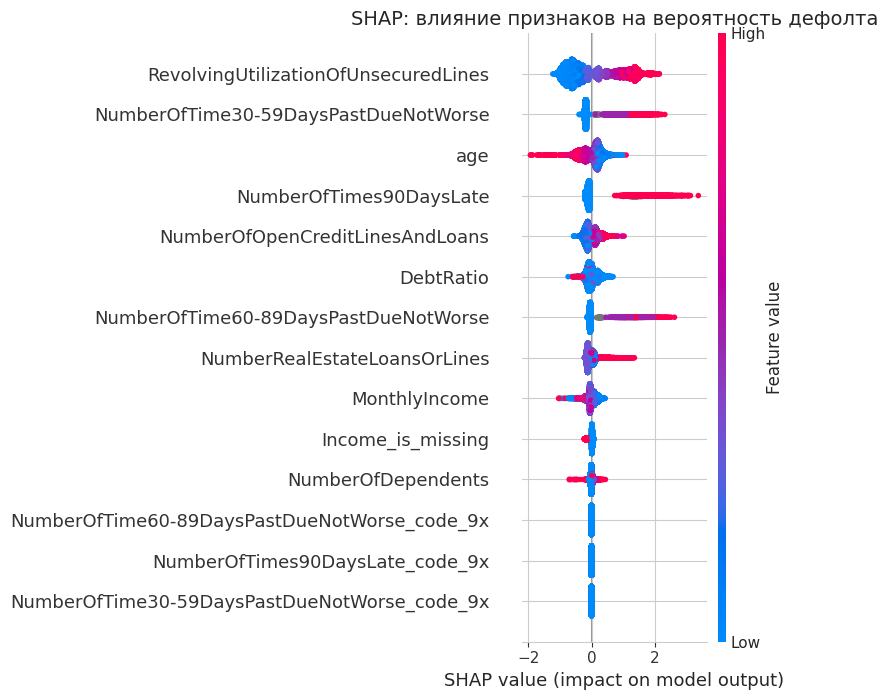

график сохранен


In [9]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_val)

# для бин классификации LightGBM возвращ список из двух массивов
# нужен массив для класса 1 (дефолт)
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_to_plot, X_val, show=False)
plt.title("SHAP: влияние признаков на вероятность дефолта", fontsize=14)
plt.tight_layout()

plt.savefig('shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()

print("график сохранен")

## интерпретация SHAP
1. SHAP объясняет, как признаки повлияли на предсказание конкретного клиента (положительно или отрицательно)
2. на глобальном уровне главными драйверами дефолта являются высокая закредитованность (RevolvingUtilization) и наличие длительных просрочек (NumberOfTimes90DaysLate)
3. однако для данного конкретного клиента (отсылка на след ячейку, где мы взяли первого клиента), у кот нет просрочек и кредитной нагрузки, главными факторами риска становятся возраст (39 лет) и количество иждивенцев (2). Это позволяет бизнесу давать точечные рекомендации: "у вас все окей с кредитной историей, но ваша возрастная группа и наличие иждивенцев - это зона, за кот банк будет следить внимательнее"

локальный SHAP для одного клиента

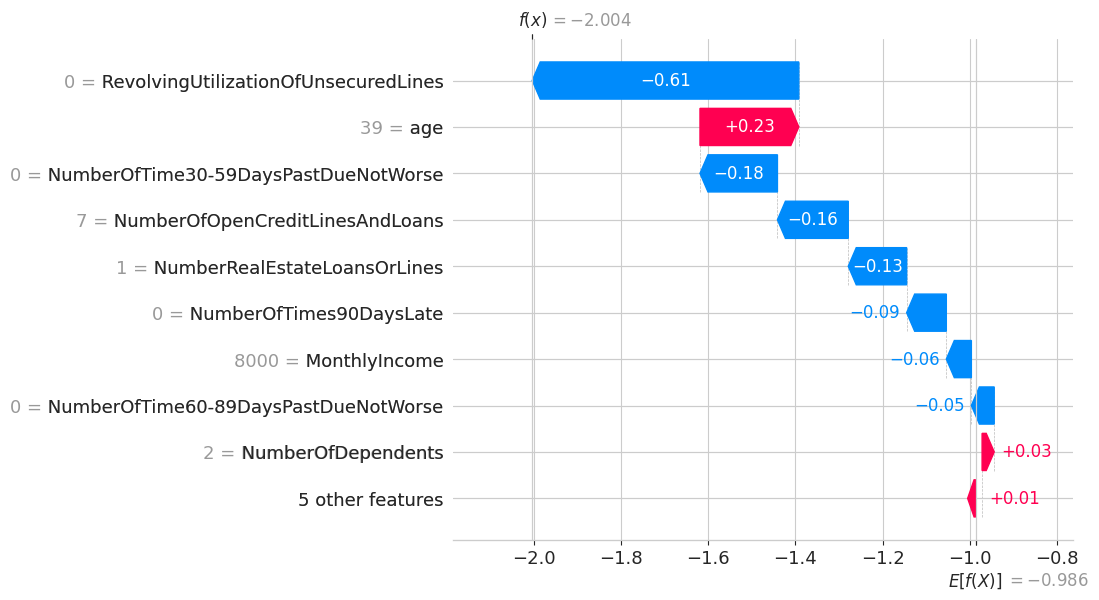

топ 3 признака, увеличивающих риск дефолта для этого клиента:
- age: 0.2269
- NumberOfDependents: 0.0278
- Income_is_missing: 0.0240


In [10]:
client_idx = 0
client_data = X_val.iloc[[client_idx]]

shap_values_single = explainer(client_data)

# Waterfall plot (поч именно этот клиент)
if len(shap_values_single.values.shape) == 3:
    shap.plots.waterfall(shap_values_single[0, :, 1])
else:
    shap.plots.waterfall(shap_values_single[0])

# топ 3 признака, кот тянут вниз
vals = shap_values_single.values[0, :, 1] if len(shap_values_single.values.shape) == 3 else shap_values_single.values[0]
feature_names = X_val.columns
top_3_idx = np.argsort(vals)[-3:][::-1]

print("топ 3 признака, увеличивающих риск дефолта для этого клиента:")
for idx in top_3_idx:
    print(f"- {feature_names[idx]}: {vals[idx]:.4f}")

нак всякий случай проверка важности признаков

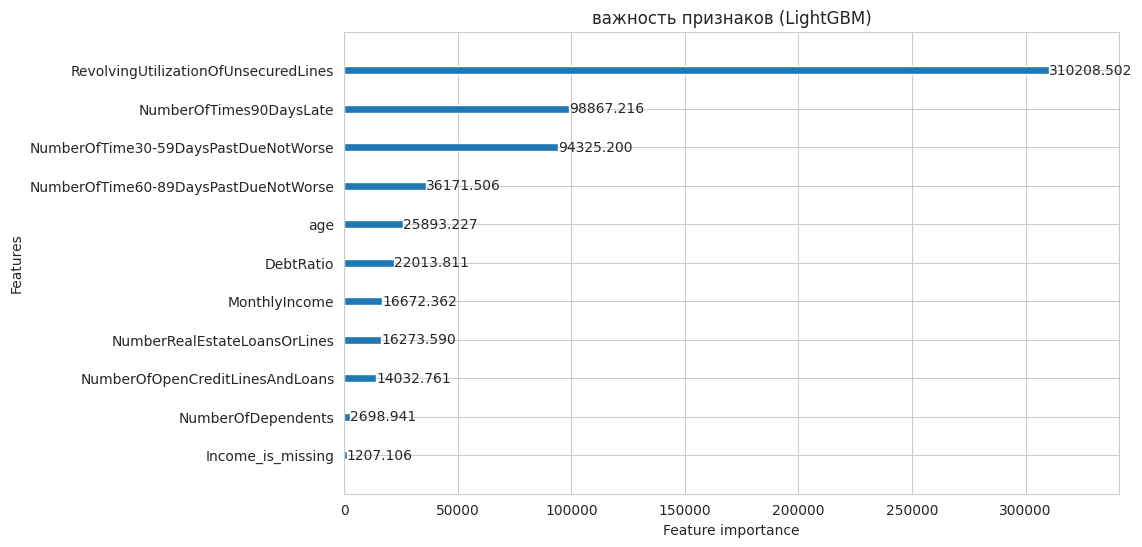

In [11]:
lgb.plot_importance(model, figsize=(10, 6), importance_type='gain')
plt.title("важность признаков (LightGBM)")
plt.show()